In [1]:
import os, uuid, hashlib, platform
# 1.填写学号（字符串！）
STUDENT_ID = "20244080112"

# 2.打印 conda 环境
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# 3.机器指纹
MACHINE_FP = hashlib.sha256((
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}"
).encode()).hexdigest()[:16]

# 4.生成唯一ID
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号]      {STUDENT_ID}")
print(f"[机器指纹]  {MACHINE_FP}")
print(f"[RUN_ID]    {RUN_ID}")

[Conda 环境] base
[学号]      20244080112
[机器指纹]  ffbafa4ebf03ea2f
[RUN_ID]    20244080112-ffbafa4ebf03ea2f


In [4]:
import numpy as np

# 任务1：创建整数、浮点数、布尔ndarray，输出dtype、shape、ndim
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1, 2.2, 3.3])
arr_bool = np.array([True, False, True])
print("整数数组 dtype:", arr_int.dtype, "shape:", arr_int.shape, "ndim:", arr_int.ndim)
print("浮点数组 dtype:", arr_float.dtype, "shape:", arr_float.shape, "ndim:", arr_float.ndim)
print("布尔数组 dtype:", arr_bool.dtype, "shape:", arr_bool.shape, "ndim:", arr_bool.ndim)
# 解释：NumPy数组是同类型连续内存存储，支持向量化运算；Python列表可以混合不同类型，是对象指针列表，运算速度慢

# 任务2：np.arange(12) 变形
a = np.arange(12)
a1 = a.reshape(3,4)
a2 = a.reshape(2,3,2)
print("(3,4):\n", a1)
print("(2,3,2):\n", a2)
# 条件：reshape前后元素总数必须相等，12 = 3*4 = 2*3*2

# 任务3：对(3,4)数组索引
print("取第2行：", a1[1])
print("取第1至第3列：\n", a1[:, 0:3])
mask = a1 > 6
print("大于6元素：", a1[mask])
print("大于6元素形状：", a1[mask].shape)

# 任务4：np.arange(10) 布尔筛选
b = np.arange(10)
cond1 = (b < 2) | (b > 7)
cond2 = (b > 3) & (b < 7)
print("小于2或大于7：", b[cond1])
print("大于3且小于7：", b[cond2])
# 也可写 np.logical_or(b<2, b>7)  np.logical_and(b>3, b<7)

# 任务5：(2,2)数组 逐元素乘法 vs 矩阵乘法
m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
print("逐元素乘法 * :\n", m1 * m2)
print("np.multiply:\n", np.multiply(m1,m2))
print("矩阵乘法 @ :\n", m1 @ m2)
print("np.matmul:\n", np.matmul(m1,m2))
# 区别：* / multiply 对应位置元素相乘；@ / matmul 是线性代数矩阵乘法，行乘列求和


整数数组 dtype: int64 shape: (4,) ndim: 1
浮点数组 dtype: float64 shape: (3,) ndim: 1
布尔数组 dtype: bool shape: (3,) ndim: 1
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
取第2行： [4 5 6 7]
取第1至第3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
大于6元素： [ 7  8  9 10 11]
大于6元素形状： (5,)
小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]
逐元素乘法 * :
 [[ 5 12]
 [21 32]]
np.multiply:
 [[ 5 12]
 [21 32]]
矩阵乘法 @ :
 [[19 22]
 [43 50]]
np.matmul:
 [[19 22]
 [43 50]]


In [5]:
import numpy as np

# 任务1：生成1000个均值70，标准差10成绩，clip限制0~100
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数：", len(scores))
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())
print("极差：", scores.max() - scores.min())

# 任务2：np.arange(1,11) 不放回抽取5个，均匀抽样 + 加权抽样
arr = np.arange(1,11)
uniform_sample = np.random.choice(arr, size=5, replace=False)
print("均匀不放回抽样：", uniform_sample)
# 按数值大小加权，数值越大权重越高
weights = arr / arr.sum()
weight_sample = np.random.choice(arr, size=5, replace=False, p=weights)
print("加权不放回抽样：", weight_sample)

# 任务3：随机排列保留原数组 vs 原地打乱
orig = np.array([1,2,3,4,5])
perm_arr = np.random.permutation(orig)
print("原数组(permutation后不变):", orig)
print("permutation新数组:", perm_arr)
orig2 = np.array([1,2,3,4,5])
np.random.shuffle(orig2)
print("shuffle原地打乱后原数组:", orig2)
# 区别：permutation返回新数组，原数组不变；shuffle直接修改原数组

# 任务4：第10、20、30个值设为nan，对比普通均值与忽略nan均值
scores_nan = scores.copy()
scores_nan[[10,20,30]] = np.nan
mean_normal = scores_nan.mean()
mean_nan_ignore = np.nanmean(scores_nan)
nan_count = np.isnan(scores_nan).sum()
print("普通均值（含nan）：", mean_normal)
print("忽略nan均值：", mean_nan_ignore)
print("缺失值个数：", nan_count)
# 说明：普通mean遇到nan直接返回nan，nan会污染统计结果，需要nanmean跳过

# 任务5：内存表格变量（这里保存为numpy结构化数组，不写磁盘）
table = np.rec.array([(i, scores_nan[i]) for i in range(len(scores_nan))], names='idx,score')
print("内存表格前5行：\n", table[:5])


样本数： 1000
最小值： 37.58732659930927
最大值： 100.0
均值： 70.18400443523215
标准差： 9.755086339034765
极差： 62.41267340069073
均匀不放回抽样： [ 4  9  2  6 10]
加权不放回抽样： [10  2  8  9  6]
原数组(permutation后不变): [1 2 3 4 5]
permutation新数组: [5 1 3 2 4]
shuffle原地打乱后原数组: [1 5 2 4 3]
普通均值（含nan）： nan
忽略nan均值： 70.18054081303245
缺失值个数： 3
内存表格前5行：
 [(0, 74.96714153) (1, 68.61735699) (2, 76.47688538) (3, 85.23029856)
 (4, 67.65846625)]


方程组解 x,y =  [2. 3.]
验证 A@sol =  [9. 8.]
正根求解成功? True 结果： [1.41421356] 函数值： [-8.8817842e-16]
负根求解成功? True 结果： [-1.41421356] 函数值： [-8.8817842e-16]
极小点x= [-0.50000001] 最小值= 1.75
t统计量： -8.55145994324873 p值： 3.292961428703696e-15
0.05显著性水平：拒绝原假设，两组均值存在显著差异


D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6

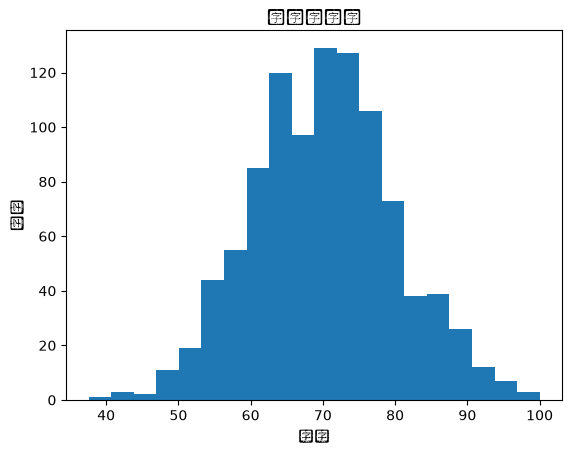

D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 31665 (\N{CJK UNIFIED IDEOGRAPH-7BB1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6

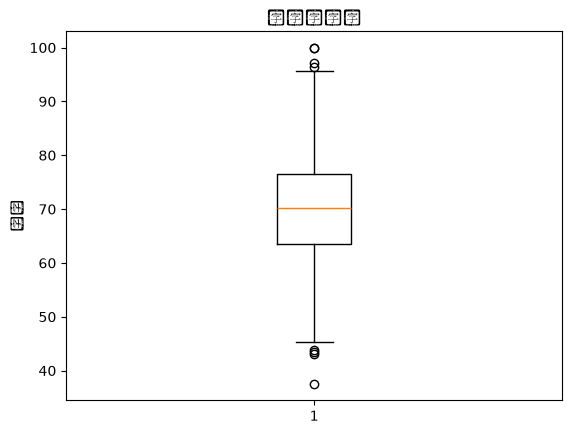

D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\l6w7x\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25240 (\N{CJK UNIFIED IDEOGRAPH-6298}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


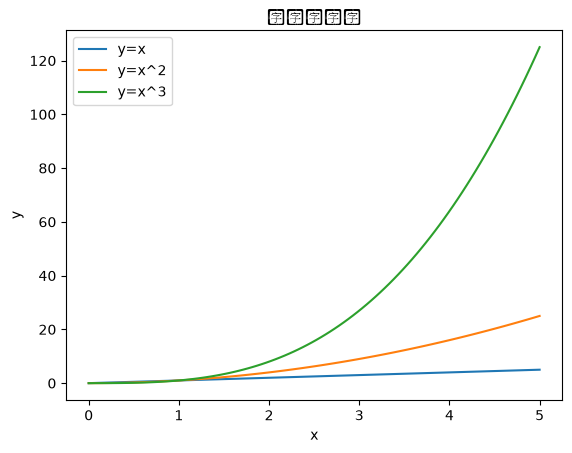

In [9]:
import numpy as np
from scipy.linalg import solve
from scipy.optimize import root, minimize
from scipy import stats
import matplotlib.pyplot as plt

# 任务1：解线性方程组 3x+y=9 ; x+2y=8
A = np.array([[3,1],[1,2]])
B = np.array([9,8])
sol = solve(A,B)
print("方程组解 x,y = ", sol)
# 验证
print("验证 A@sol = ", A @ sol)

# 任务2：求 x^2 -2 =0 正负根
def f(x):
    return x**2 - 2
res_pos = root(f, x0=1)
res_neg = root(f, x0=-1)
print("正根求解成功?", res_pos.success, "结果：", res_pos.x, "函数值：", f(res_pos.x))
print("负根求解成功?", res_neg.success, "结果：", res_neg.x, "函数值：", f(res_neg.x))

# 任务3：minimize 求 f(x)=x²+x+2 最小值
def fun(x):
    return x**2 + x + 2
res_min = minimize(fun, x0=0)
print("极小点x=", res_min.x, "最小值=", res_min.fun)
# 解析解：导数2x+1=0，x=-0.5，最小值= (-0.5)**2 + (-0.5)+2 =1.75

# 任务4：独立样本t检验
np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_val = stats.ttest_ind(sample1, sample2)
print("t统计量：", t_stat, "p值：", p_val)
if p_val < 0.05:
    print("0.05显著性水平：拒绝原假设，两组均值存在显著差异")
else:
    print("0.05显著性水平：不能拒绝原假设")

# 任务5：绘图
valid_score = scores_nan[~np.isnan(scores_nan)]
plt.figure()
plt.hist(valid_score, bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")
plt.show()

plt.figure()
plt.boxplot(valid_score)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.show()

x = np.linspace(0,5,100)
plt.figure()
plt.plot(x, x, label="y=x")
plt.plot(x, x**2, label="y=x^2")
plt.plot(x, x**3, label="y=x^3")
plt.title("函数折线图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


In [11]:
import pandas as pd
import io

# 任务1 创建DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")
df["Total"] = df[["Math","English","Python"]].sum(axis=1)
df["Average"] = df[["Math","English","Python"]].mean(axis=1)
print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("前3行：\n", df.head(3))
print("基本统计信息：\n", df.describe())

# 任务2 loc 和 iloc 读取Carol，筛选平均分>=80
print("loc读取Carol：\n", df.loc["Carol"])
print("iloc读取Carol：\n", df.iloc[2])
print("平均分不低于80学生：\n", df[df["Average"] >= 80])

# 任务3 mean(axis=0) 列均值，mean(axis=1)行均值
print("三科列均值：\n", df[["Math","English","Python"]].mean(axis=0))
print("每名学生行均值：\n", df[["Math","English","Python"]].mean(axis=1))

# 任务4 apply求最高分，agg聚合，rank排名
df["MaxScore"] = df[["Math","English","Python"]].apply(lambda row: row.max(), axis=1)
agg_res = df[["Math","English","Python"]].agg(["min","mean","max"])
print("agg结果：\n", agg_res)
print("Math列排名：\n", df["Math"].rank())

# 任务5 按Group分组统计人数与三科平均分，transform增加组内Python平均分
group_stat = df.groupby("Group")[["Math","English","Python"]].agg(["count","mean"])
print("分组统计：\n", group_stat)
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("增加组Python平均分后：\n", df)

# 任务6 filter保留Python组平均分>=80的组
group_py_mean = df.groupby("Group")["Python"].mean()
keep_groups = group_py_mean[group_py_mean >= 80].index
df_filter = df[df["Group"].isin(keep_groups)]
print("保留组和学生：\n", df_filter)

# 任务7 协方差矩阵、皮尔森相关矩阵
score_df = df[["Math","English","Python"]]
cov_mat = score_df.cov()
corr_mat = score_df.corr()
print("协方差矩阵：\n", cov_mat)
print("皮尔森相关系数矩阵：\n", corr_mat)
# 解释：协方差>0代表两科正相关，数值越大同向变化程度越强；相关系数范围[-1,1]，越接近1线性正相关越强，-1负相关越强，0无线性相关


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息：
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000
loc读取Carol：
 Group              B
Math     